--> Searching for DRIAMS metadata tables in /kaggle/input ...
Found 8 metadata table(s):
  - /kaggle/input/datasets/drscarlat/driams/DRIAMS-A/id/2015/2015_clean.csv
  - /kaggle/input/datasets/drscarlat/driams/DRIAMS-A/id/2015/2015_strat.csv
  - /kaggle/input/datasets/drscarlat/driams/DRIAMS-A/id/2016/2016_clean.csv
  - /kaggle/input/datasets/drscarlat/driams/DRIAMS-A/id/2016/2016_strat.csv
  - /kaggle/input/datasets/drscarlat/driams/DRIAMS-A/id/2017/2017_clean.csv
  - /kaggle/input/datasets/drscarlat/driams/DRIAMS-A/id/2017/2017_strat.csv
  - /kaggle/input/datasets/drscarlat/driams/DRIAMS-A/id/2018/2018_clean.csv
  - /kaggle/input/datasets/drscarlat/driams/DRIAMS-A/id/2018/2018_strat.csv

Total aggregated records: 222514 rows, 99 columns

Target Drug: Ciprofloxacin
Cleaned E. coli Cohort Size: 10204
Purged 41 drug outcome columns to prevent leakage.
Retained Features (49): ['species', 'laboratory_species', 'Fluconazole', 'Amphotericin B', 'Caspofungin', 'Micafungin', 'Itraconazole', '5

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [33, 34, 36, 37, 38] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(



            CLINICAL TEST SET EVALUATION         
                 precision    recall  f1-score   support

Susceptible (S)       0.85      0.93      0.88      1439
  Resistant (R)       0.77      0.59      0.67       602

       accuracy                           0.83      2041
      macro avg       0.81      0.76      0.78      2041
   weighted avg       0.82      0.83      0.82      2041

ROC-AUC:  0.7974
PR-AUC:   0.6618

--> Generating SHAP attribution plots...


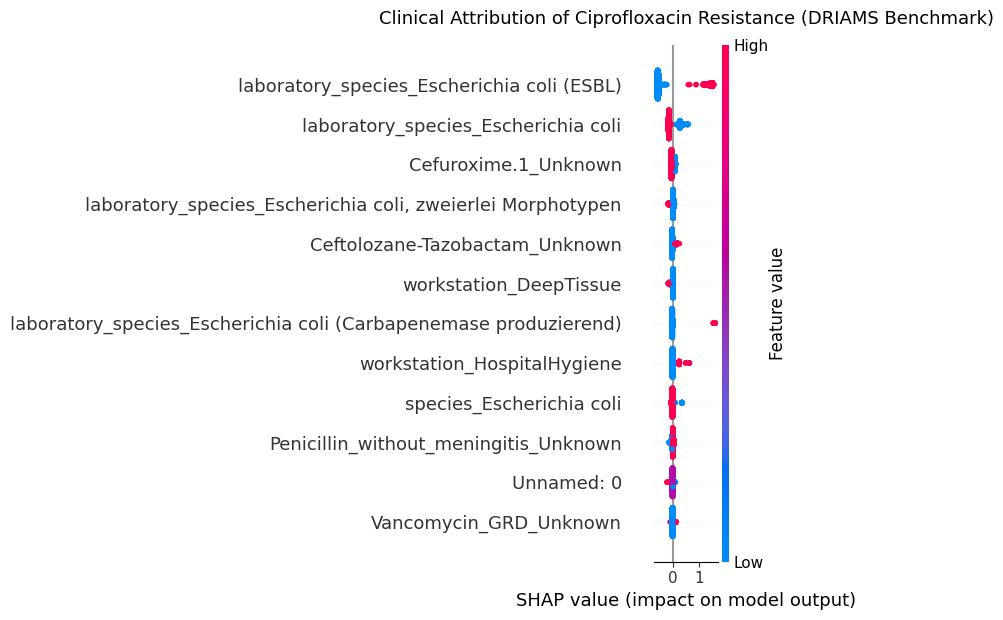

Saved SHAP plot to: /kaggle/working/shap_driams_ciprofloxacin.png


In [11]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score
from xgboost import XGBClassifier
import shap

# ==========================================
# 1. DYNAMIC & ROBUST METADATA DISCOVERY
# ==========================================
print("--> Searching for DRIAMS metadata tables in /kaggle/input ...")

# Recursively locate all CSV and TSV files in the Kaggle input directory
all_tabular_files = []
for root, _, files in os.walk("/kaggle/input"):
    for f in files:
        if f.endswith((".csv", ".tsv")):
            all_tabular_files.append(os.path.join(root, f))

# Filter specifically for DRIAMS-A metadata/id tables
meta_files = [
    f for f in all_tabular_files 
    if "driams-a" in f.lower() and ("id" in f.lower() or "clean" in f.lower())
]

# Fallback: if DRIAMS-A specific path is not matched, select any table from DRIAMS containing id/clean
if not meta_files:
    meta_files = [
        f for f in all_tabular_files 
        if "driams" in f.lower() and ("id" in f.lower() or "clean" in f.lower() or "meta" in f.lower())
    ]

# Final fallback: use all discovered tabular files if no specific names matched
if not meta_files:
    meta_files = all_tabular_files

print(f"Found {len(meta_files)} metadata table(s):")
for f in meta_files:
    print(f"  - {f}")

if not meta_files:
    raise FileNotFoundError("No CSV or TSV files found under /kaggle/input. Ensure the dataset is added to your notebook.")

# ==========================================
# 2. LOAD & AGGREGATE ANNUAL COHORTS
# ==========================================
dfs = []
for file_path in sorted(meta_files):
    try:
        # Use python engine with auto-separator detection
        temp_df = pd.read_csv(file_path, sep=None, engine="python")
        temp_df["source_file"] = os.path.basename(file_path)
        dfs.append(temp_df)
    except Exception as e:
        print(f"Skipping {file_path} due to read error: {e}")

if not dfs:
    raise ValueError("All discovered metadata files failed to load.")

df_raw = pd.concat(dfs, ignore_index=True)
print(f"\nTotal aggregated records: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")

# ==========================================
# 3. SELECT TARGET & FILTER COHORT
# ==========================================
TARGET_DRUG = "Ciprofloxacin"

# Locate species column dynamically
species_candidates = [c for c in df_raw.columns if "species" in c.lower()]
if not species_candidates:
    raise ValueError(f"Species column not found. Available columns: {list(df_raw.columns[:20])}")
SPECIES_COL = species_candidates[0]

if TARGET_DRUG not in df_raw.columns:
    # Auto-detect available antibiotic outcome columns if Ciprofloxacin is missing
    available_drugs = [c for c in df_raw.columns if df_raw[c].dropna().isin(["R", "S", "I"]).any()]
    if not available_drugs:
        raise KeyError(f"Neither '{TARGET_DRUG}' nor any other drug test columns were found.")
    TARGET_DRUG = available_drugs[0]
    print(f"Notice: Switched target to available drug column '{TARGET_DRUG}'")

# Filter for E. coli isolates with a valid test outcome
cohort = df_raw[df_raw[SPECIES_COL].astype(str).str.contains("coli", case=False, na=False)].copy()
cohort = cohort.dropna(subset=[TARGET_DRUG]).copy()

# Binary Target: 1 = Resistant ('R') / Intermediate ('I'), 0 = Susceptible ('S')
cohort["y_true"] = cohort[TARGET_DRUG].isin(["R", "I"]).astype(int)

# ==========================================
# 4. PURGE LEAKAGE COLUMNS & SELECT FEATURES
# ==========================================
# Remove any other antibiotic columns containing phenotypic labels ('R', 'S', 'I')
drug_leakage_cols = [
    col for col in cohort.columns 
    if cohort[col].dropna().isin(["R", "S", "I"]).any()
]

# Exclude identifiers, sample codes, spectrum names, and targets
id_cols = [
    c for c in cohort.columns 
    if any(k in c.lower() for k in ["code", "id", "spectrum", "sample", "target", "y_true"])
]

# Clinical and contextual metadata features
feature_candidates = [c for c in cohort.columns if c not in drug_leakage_cols and c not in id_cols]
valid_features = [c for c in feature_candidates if cohort[c].notnull().mean() > 0.10]

print(f"\nTarget Drug: {TARGET_DRUG}")
print(f"Cleaned E. coli Cohort Size: {len(cohort)}")
print(f"Purged {len(drug_leakage_cols)} drug outcome columns to prevent leakage.")
print(f"Retained Features ({len(valid_features)}): {valid_features}")

X = cohort[valid_features].copy()
y = cohort["y_true"].copy()

print("\nTarget Class Distribution:")
print(y.value_counts(normalize=True))

# ==========================================
# 5. PREPROCESSING PIPELINE
# ==========================================
cat_cols = X.select_dtypes(include=["object"]).columns.tolist()
num_cols = X.select_dtypes(include=[np.number]).columns.tolist()

for col in cat_cols:
    X[col] = X[col].fillna("Unknown").astype(str)
for col in num_cols:
    X[col] = X[col].fillna(X[col].median())

# 80/20 Stratified Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"), cat_cols)
    ],
    remainder="passthrough"
)

X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)

# Feature names for explainability
cat_encoder = preprocessor.named_transformers_["cat"]
cat_names = cat_encoder.get_feature_names_out(cat_cols).tolist() if cat_cols else []
all_features = cat_names + num_cols

# ==========================================
# 6. TRAIN IMBALANCE-AWARE XGBOOST
# ==========================================
neg_count, pos_count = np.bincount(y_train)
scale_pos_weight = neg_count / max(1, pos_count)

model = XGBClassifier(
    n_estimators=160,
    max_depth=4,
    learning_rate=0.04,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=42
)
model.fit(X_train_proc, y_train)

# ==========================================
# 7. CLINICAL TEST EVALUATION
# ==========================================
probs = model.predict_proba(X_test_proc)[:, 1]
preds = (probs >= 0.50).astype(int)

print("\n" + "=" * 55)
print("            CLINICAL TEST SET EVALUATION         ")
print("=" * 55)
print(classification_report(y_test, preds, target_names=["Susceptible (S)", "Resistant (R)"]))
print(f"ROC-AUC:  {roc_auc_score(y_test, probs):.4f}")
print(f"PR-AUC:   {average_precision_score(y_test, probs):.4f}")

# ==========================================
# 8. SHAP EXPLAINABILITY VISUALIZATION
# ==========================================
print("\n--> Generating SHAP attribution plots...")
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test_proc)

plt.figure(figsize=(10, 6))
shap.summary_plot(
    shap_values,
    X_test_proc,
    feature_names=all_features,
    max_display=12,
    show=False
)
plt.title(f"Clinical Attribution of {TARGET_DRUG} Resistance (DRIAMS Benchmark)", fontsize=13, pad=15)
plt.tight_layout()

output_path = "/kaggle/working/shap_driams_ciprofloxacin.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved SHAP plot to: {output_path}")